# Used Tractor Auction Prices: Data Cleaning and Exploratory Analysis

This notebook prepares the auction data for price modelling and carries out the exploratory analysis that motivates the modelling decisions.

The notebook has five aims:

1. define a reproducible sample of realised tractor auction sales;
2. quantify missingness and data-quality limitations before modelling;
3. remove repeated scrapes without discarding genuine high-price observations;
4. examine price patterns across currencies, age, usage, manufacturer, model series and equipment;
5. investigate potentially valuable but sparsely recorded fields, especially `horsepower` and `transmission`, before deciding whether they can be used as predictors.

The exploratory stage is treated as a substantive part of the project rather than only as preparation for the predictive model. Descriptive relationships are interpreted cautiously: they can reveal structure and data limitations, but they do not establish causal effects.

**Important data note:** `observed_date` records when a listing was scraped rather than the auction date. The same auction result can therefore appear in repeated scrape/source records, sometimes across more than one observed date. `observed_date` is not used as a predictor.

## 1. Packages and file locations

Only standard data-analysis packages are required in this notebook. Before running this notebook, make sure that **market_listings_new.csv** is in the same directory as this notebook

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
# Input file supplied for the project.
RAW_DATA_PATH = Path("market_listings_new.csv")

# Files created by this notebook.
CLEAN_DATA_PATH = Path("cleaned_tractors.csv")
FIGURE_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Analysis settings

The explicit lists below make the cleaning assumptions easy to audit.

In [3]:
AUCTION_CHANNELS = ["auction_rba", "auction_cheffins"]
REFERENCE_YEAR = 2026

# These fields are listing specification indicators.
BOOLEAN_FEATURES = [
    "front_pto",
    "front_loader",
    "front_linkage",
    "front_axle_suspension",
    "cab_suspension",
    "cab",
    "air_conditioning",
    "air_brakes",
    "isobus",
    "adblue",
    "creeper",
    "trailer_hitch",
    "load_sensing",
    "differential_lock",
    "dual_tires",
    "rear_view_camera",
    "high_flow_hydraulics",
]

## 3. Load the raw data

In [4]:
raw = pd.read_csv(RAW_DATA_PATH, low_memory=False)
print(f"Raw data: {raw.shape[0]:,} rows and {raw.shape[1]} columns")
raw.head()

Raw data: 354,607 rows and 46 columns


,market_id,channel,price_type,source,country,make,model_series,variant,equipment_type,year,hours,horsepower,price,currency,vat_basis,vat_status,price_excl_vat,observed_date,transmission,drive,gps,gps_activation,gps_brand,front_pto,front_loader,front_linkage,front_axle_suspension,cab_suspension,cab,air_conditioning,air_brakes,isobus,adblue,creeper,trailer_hitch,load_sensing,differential_lock,dual_tires,rear_view_camera,high_flow_hydraulics,emissions_tier,tyres_front,tyres_rear,tyre_depth_front,tyre_depth_rear,status
0,market_000001,classified,asking,landwirt,Austria,Holder,AM 2,NaN,tractor,1972,NaN,18.000,"5,000.000",EUR,net,VAT not applicable,NaN,04/03/2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,removed
1,market_000002,classified,asking,landwirt,Austria,Holder,A60 pickerlfrei 25 km/h,NaN,tractor,1980,"5,127.000",50.000,"8,460.000",GBP,net,VAT not applicable,NaN,13/02/2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,removed
2,market_000003,classified,asking,landwirt,Greece,Holder,C 340 digital all-wheel drive articulated trac...,NaN,tractor,2009,"4,600.000",42.000,"16,000.000",EUR,net,VAT not applicable,NaN,04/03/2026,NaN,4WD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,removed
3,market_000004,classified,asking,landwirt,Austria,Holder,AG 35,NaN,tractor,1972,"1,234.000",35.000,"8,573.000",GBP,net,VAT not applicable,NaN,01/02/2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,removed
4,market_000005,classified,asking,landwirt,Germany,Holder,E12 Einachsschlepper,NaN,tractor,1959,NaN,12.000,950.000,EUR,net,VAT not applicable,NaN,04/03/2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,removed


## 4. Keep realised tractor auction sales

Classified advertisements are asking prices rather than realised sale prices. The analysis therefore keeps only sold tractors from the two auction channels.

In [5]:
auction_tractors = raw.loc[
    raw["channel"].isin(AUCTION_CHANNELS)
    & raw["price_type"].eq("sold")
    & raw["equipment_type"].eq("tractor")
].copy()

print(f"Sold auction tractors before cleaning: {len(auction_tractors):,}")

Sold auction tractors before cleaning: 40,326


## 5. Record missingness before cleaning

Missingness is examined before any filtering or imputation because it determines whether a field can be used directly, requires a defensible treatment, or is too incomplete for the main model. The full missingness table is saved so that excluded fields remain visible in the audit trail.

In [6]:
missing_before = (
    auction_tractors.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .to_frame()
)

missing_before.to_csv(TABLE_DIR / "01_missingness_before_cleaning.csv")
missing_before.head(25)

,missing_percent
price_excl_vat,100.000
tyres_rear,100.000
tyres_front,100.000
vat_status,100.000
tyre_depth_rear,99.943
tyre_depth_front,99.943
dual_tires,99.164
creeper,98.748
emissions_tier,98.344
front_linkage,98.336


## 6. Clean text fields

Leading/trailing spaces and repeated internal spaces are removed from the main text variables. Currency codes are stored in upper case.

In [7]:
TEXT_COLUMNS = ["make", "model_series", "currency", "country"]

for column in TEXT_COLUMNS:
    auction_tractors[column] = (
        auction_tractors[column]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

auction_tractors["currency"] = auction_tractors["currency"].str.upper()
auction_tractors["country"] = auction_tractors["country"].fillna("UNKNOWN")

# Transmission is retained for EDA only. It is cleaned here so that category
# counts and price comparisons are not split by trivial whitespace differences.
auction_tractors["transmission"] = (
    auction_tractors["transmission"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

## 7. Impute missing drive values

Domain guidance supplied with the project states that missing `drive` values should be treated as **4WD**. This rule is applied directly.

No separate missing-drive category is created.

In [8]:
auction_tractors["drive"] = (
    auction_tractors["drive"]
    .astype("string")
    .str.strip()
    .str.upper()
)

missing_drive = auction_tractors["drive"].isna().sum()
auction_tractors["drive"] = auction_tractors["drive"].fillna("4WD")

print(f"Missing drive values replaced with 4WD: {missing_drive:,}")
print(auction_tractors["drive"].value_counts())

Missing drive values replaced with 4WD: 22,079
drive
4WD    39070
2WD     1256
Name: count, dtype: Int64


## 8. Clean Boolean specification fields

For the explicit listing-specification indicators, a recorded `True` means that the feature was present in the scraped specification data. Blank entries are stored as `False`.

The list is specified manually rather than inferred from the data, which prevents completely empty columns from being accidentally treated as Boolean variables.

In [9]:
for column in BOOLEAN_FEATURES:
    auction_tractors[column] = auction_tractors[column].fillna(False).astype(bool)

C:\Users\Me\AppData\Local\Temp\ipykernel_5044\2067788180.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  auction_tractors[column] = auction_tractors[column].fillna(False).astype(bool)
C:\Users\Me\AppData\Local\Temp\ipykernel_5044\2067788180.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  auction_tractors[column] = auction_tractors[column].fillna(False).astype(bool)
C:\Users\Me\AppData\Local\Temp\ipykernel_5044\2067788180.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future versi

## 9. Convert the numerical fields

`horsepower` is converted to numeric even though it is not included in the final modelling feature set. This allows its coverage and relationship with price to be assessed explicitly rather than dropping it without analysis.

In [10]:
for column in ["price", "year", "hours", "horsepower"]:
    auction_tractors[column] = pd.to_numeric(
        auction_tractors[column], errors="coerce"
    )

## 10. Basic validity checks

Only observations that cannot be used meaningfully are removed:

- price must be positive;
- currency, make, model series and manufacture year must be available;
- manufacture year cannot be later than 2026.

Missing `hours` values are **not** removed. They are imputed later using the training data only.

High auction prices are also not removed automatically. A genuine tractor sale can be unusually expensive, so extreme prices are inspected rather than deleted by an arbitrary IQR rule.

In [11]:
invalid_price = auction_tractors["price"].isna() | auction_tractors["price"].le(0)
missing_identity = auction_tractors[[
    "currency", "make", "model_series", "year"
]].isna().any(axis=1)
future_year = auction_tractors["year"].gt(REFERENCE_YEAR)

quality_table = pd.DataFrame({
    "issue": [
        "Invalid or non-positive price",
        "Missing currency/make/model series/year",
        f"Manufacture year later than {REFERENCE_YEAR}",
    ],
    "rows": [
        int(invalid_price.sum()),
        int(missing_identity.sum()),
        int(future_year.sum()),
    ],
})

quality_table.to_csv(TABLE_DIR / "02_data_quality_checks.csv", index=False)
quality_table

,issue,rows
0,Invalid or non-positive price,0
1,Missing currency/make/model series/year,0
2,Manufacture year later than 2026,9


In [12]:
valid_tractors = auction_tractors.loc[
    ~invalid_price & ~missing_identity & ~future_year
].copy()

print(f"Rows after validity checks: {len(valid_tractors):,}")

Rows after validity checks: 40,317


## 11. Select modelling fields before duplicate removal

`observed_date`, scrape identifiers and source metadata are intentionally excluded before duplicate removal because they describe the scrape rather than the tractor sale.

`model_series` is retained. This prevents different tractor models from being collapsed simply because their other recorded characteristics are identical.

`horsepower` and `transmission` are deliberately **not** included in the duplicate key or final modelling columns. They are analysed separately after duplicate removal because their coverage is very low; including them in the duplicate key would incorrectly preserve repeated records whenever one scrape recorded a specification and another did not.

In [13]:
MODELLING_COLUMNS = [
    "country",
    "make",
    "model_series",
    "year",
    "hours",
    "price",
    "currency",
    "drive",
] + BOOLEAN_FEATURES

model_data = valid_tractors[MODELLING_COLUMNS].copy()

## 12. Remove repeated records

In [14]:
rows_before_deduplication = len(model_data)

model_data = model_data.drop_duplicates().reset_index(drop=True)

rows_after_deduplication = len(model_data)
rows_removed_as_duplicates = rows_before_deduplication - rows_after_deduplication

print(f"Rows before duplicate removal: {rows_before_deduplication:,}")
print(f"Repeated scrapes removed:       {rows_removed_as_duplicates:,}")
print(f"Final unique observations:      {rows_after_deduplication:,}")

Rows before duplicate removal: 40,317
Repeated scrapes removed:       17,460
Final unique observations:      22,857


## 13. Recover the most complete horsepower/transmission record for EDA

The final modelling sample is defined only by the modelling fields above. For exploratory analysis of `horsepower` and `transmission`, repeated scrapes are collapsed using the **same modelling duplicate key**, while retaining the scrape with the most complete values for those two fields.

This does not change the modelling sample size or add either field to the predictive model. It simply avoids throwing away a recorded horsepower or transmission value when another scrape of the same sale is blank.

In [15]:
specification_candidates = valid_tractors[
    MODELLING_COLUMNS + ["horsepower", "transmission"]
].copy()

specification_candidates["_specification_completeness"] = (
    specification_candidates["horsepower"].notna().astype(int)
    + specification_candidates["transmission"].notna().astype(int)
)

eda_data = (
    specification_candidates
    .sort_values("_specification_completeness", ascending=False)
    .drop_duplicates(subset=MODELLING_COLUMNS, keep="first")
    .drop(columns="_specification_completeness")
    .reset_index(drop=True)
)

assert len(eda_data) == len(model_data)

print(f"EDA rows aligned to modelling sample: {len(eda_data):,}")
print(
    "Horsepower available:",
    f"{eda_data['horsepower'].notna().sum():,}",
    f"({100 * eda_data['horsepower'].notna().mean():.1f}%)",
)
print(
    "Transmission available:",
    f"{eda_data['transmission'].notna().sum():,}",
    f"({100 * eda_data['transmission'].notna().mean():.1f}%)",
)

EDA rows aligned to modelling sample: 22,857
Horsepower available: 2,947 (12.9%)
Transmission available: 3,666 (16.0%)


## 14. Cleaning audit table

The audit table records how the sample size changes at each major step.

In [16]:
cleaning_audit = pd.DataFrame({
    "stage": [
        "Raw data",
        "Sold auction tractors",
        "After validity checks",
        "After duplicate removal",
    ],
    "rows": [
        len(raw),
        len(auction_tractors),
        len(valid_tractors),
        len(model_data),
    ],
})

cleaning_audit["removed_since_previous"] = (
    cleaning_audit["rows"].shift(1) - cleaning_audit["rows"]
)
cleaning_audit.loc[0, "removed_since_previous"] = np.nan

cleaning_audit.to_csv(TABLE_DIR / "03_cleaning_audit.csv", index=False)
cleaning_audit

,stage,rows,removed_since_previous
0,Raw data,354607,NaN
1,Sold auction tractors,40326,"314,281.000"
2,After validity checks,40317,9.000
3,After duplicate removal,22857,"17,460.000"


## 15. Final missingness and specification coverage

Missingness in the modelling variables is reported separately from the two excluded specification fields. This makes the exclusion of horsepower and transmission an explicit data-coverage decision rather than an implicit modelling choice.

In [17]:
missing_after = (
    model_data.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .to_frame()
)

missing_after.to_csv(TABLE_DIR / "04_missingness_after_cleaning.csv")

specification_coverage = pd.DataFrame({
    "field": ["hours", "horsepower", "transmission"],
    "available_rows": [
        int(model_data["hours"].notna().sum()),
        int(eda_data["horsepower"].notna().sum()),
        int(eda_data["transmission"].notna().sum()),
    ],
    "available_percent": [
        100 * model_data["hours"].notna().mean(),
        100 * eda_data["horsepower"].notna().mean(),
        100 * eda_data["transmission"].notna().mean(),
    ],
})
specification_coverage["missing_percent"] = 100 - specification_coverage["available_percent"]
specification_coverage["modelling_decision"] = [
    "Retained; median-imputed using training data plus missingness indicator",
    "Excluded from model; retained for EDA because coverage is too sparse",
    "Excluded from model; retained for EDA because coverage is too sparse",
]

specification_coverage.to_csv(
    TABLE_DIR / "05_key_specification_coverage.csv", index=False
)

display(missing_after.head(10))
specification_coverage

,missing_percent
hours,25.060
country,0.000
cab,0.000
rear_view_camera,0.000
dual_tires,0.000
differential_lock,0.000
load_sensing,0.000
trailer_hitch,0.000
creeper,0.000
adblue,0.000


,field,available_rows,available_percent,missing_percent,modelling_decision
0,hours,17129,74.940,25.060,Retained; median-imputed using training data p...
1,horsepower,2947,12.893,87.107,Excluded from model; retained for EDA because ...
2,transmission,3666,16.039,83.961,Excluded from model; retained for EDA because ...


# Exploratory Data Analysis

## 16. Price distribution

Auction prices are strongly right-skewed. The log transformation compresses the upper tail and is therefore examined alongside the raw price distribution.

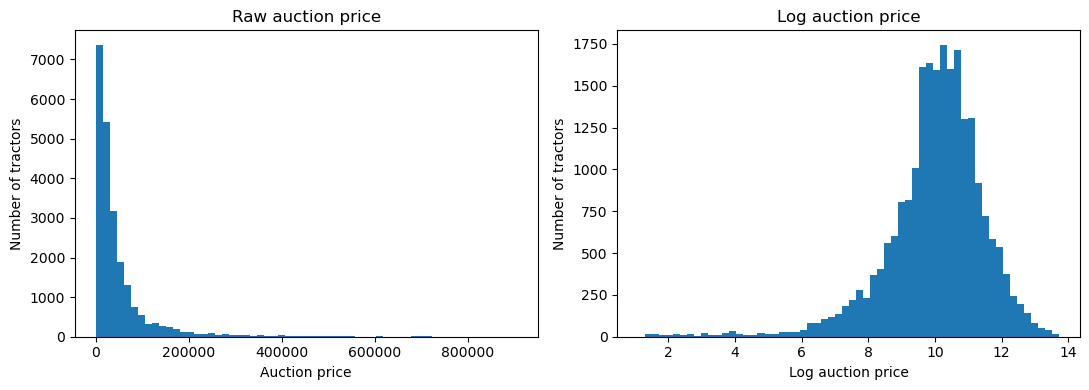

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(model_data["price"], bins=60)
axes[0].set_xlabel("Auction price")
axes[0].set_ylabel("Number of tractors")
axes[0].set_title("Raw auction price")

axes[1].hist(np.log(model_data["price"]), bins=60)
axes[1].set_xlabel("Log auction price")
axes[1].set_ylabel("Number of tractors")
axes[1].set_title("Log auction price")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_price_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 17. Price distribution by currency

Raw prices are not directly comparable across currencies, so each currency is summarised separately.

In [19]:
price_by_currency = (
    model_data.groupby("currency")["price"]
    .agg(
        count="size",
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        minimum="min",
        maximum="max",
    )
    .sort_values("count", ascending=False)
)

price_by_currency["iqr"] = price_by_currency["q75"] - price_by_currency["q25"]
price_by_currency.to_csv(TABLE_DIR / "06_price_summary_by_currency.csv")
price_by_currency

,count,median,mean,q25,q75,minimum,maximum,iqr
currency,,,,,,,,
CAD,8461,"39,000.000","72,228.409","16,000.000","82,500.000",5.000,"905,000.000","66,500.000"
USD,8266,"23,500.000","37,331.379","13,000.000","42,000.000",5.000,"485,000.000","29,000.000"
EUR,3306,"26,000.000","34,367.656","13,500.000","47,000.000",5.000,"260,000.000","33,500.000"
GBP,2382,"6,350.500","13,579.380","1,800.000","17,000.000",3.000,"304,000.000","15,200.000"
AUD,442,"49,000.000","73,815.679","23,500.000","96,750.000",230.000,"470,000.000","73,250.000"


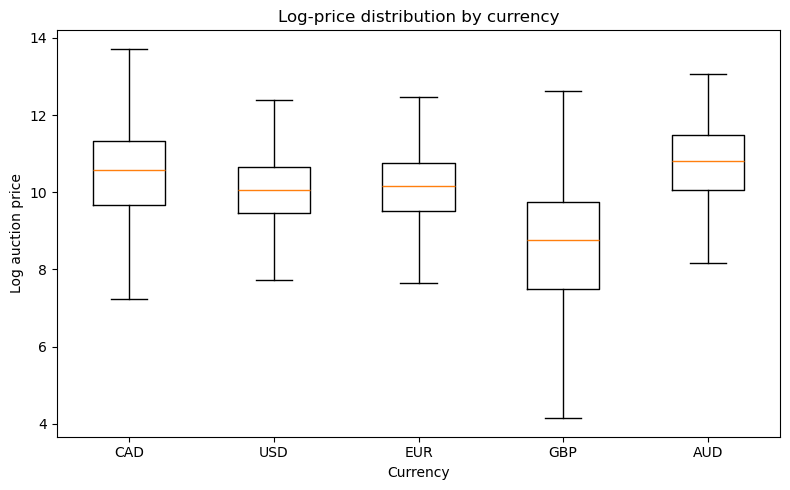

In [20]:
currencies = price_by_currency.index.tolist()
plot_data = [np.log(model_data.loc[model_data["currency"].eq(c), "price"]) for c in currencies]

plt.figure(figsize=(8, 5))
plt.boxplot(plot_data, tick_labels=currencies, showfliers=False)
plt.xlabel("Currency")
plt.ylabel("Log auction price")
plt.title("Log-price distribution by currency")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_log_price_by_currency.png", dpi=300, bbox_inches="tight")
plt.show()

The currency groups also differ markedly in sample size. This matters later when interpreting currency-specific model errors: a currency with fewer observations provides less information for both model fitting and evaluation.

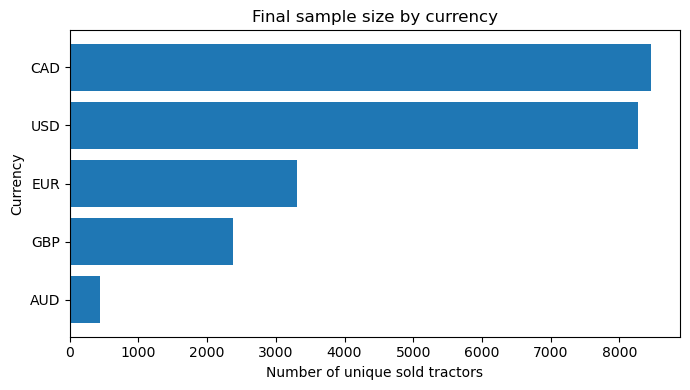

In [21]:
currency_counts = price_by_currency["count"].sort_values()

plt.figure(figsize=(7, 4))
plt.barh(currency_counts.index, currency_counts.values)
plt.xlabel("Number of unique sold tractors")
plt.ylabel("Currency")
plt.title("Final sample size by currency")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "02b_sample_size_by_currency.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 18. Relative log price for exploratory comparisons

Manufacturer, drive type and equipment comparisons can be distorted if one group is concentrated in a particular currency. For EDA only, log price is therefore centred by the median log price within each currency:

$$
\text{relative log price} = \log(P) - \operatorname{median}\{\log(P)\mid\text{currency}\}.
$$

A value above zero means that the tractor is more expensive than the median tractor in the same currency. This is an exploratory adjustment only; the formal target transformation is fitted using training data in the modelling notebook.

In [22]:
model_data["log_price"] = np.log(model_data["price"])

currency_medians = model_data.groupby("currency")["log_price"].transform("median")
model_data["relative_log_price"] = model_data["log_price"] - currency_medians

eda_data["log_price"] = np.log(eda_data["price"])
eda_currency_medians = eda_data.groupby("currency")["log_price"].transform("median")
eda_data["relative_log_price"] = eda_data["log_price"] - eda_currency_medians

## 19. Usage hours and price

The scatterplot is used to check whether the relationship between usage and price appears approximately linear.

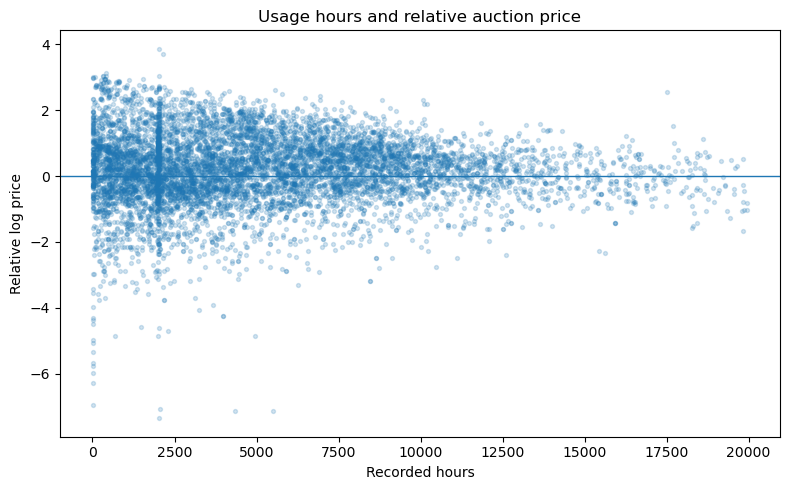

In [23]:
hours_plot = model_data.dropna(subset=["hours"]).copy()

# A sample keeps the plot readable while preserving the overall pattern.
hours_plot = hours_plot.sample(
    n=min(8000, len(hours_plot)),
    random_state=42,
)

plt.figure(figsize=(8, 5))
plt.scatter(
    hours_plot["hours"],
    hours_plot["relative_log_price"],
    s=8,
    alpha=0.20,
)
plt.axhline(0, linewidth=1)
plt.xlabel("Recorded hours")
plt.ylabel("Relative log price")
plt.title("Usage hours and relative auction price")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_price_vs_hours.png", dpi=300, bbox_inches="tight")
plt.show()

## 20. Manufacture year and price

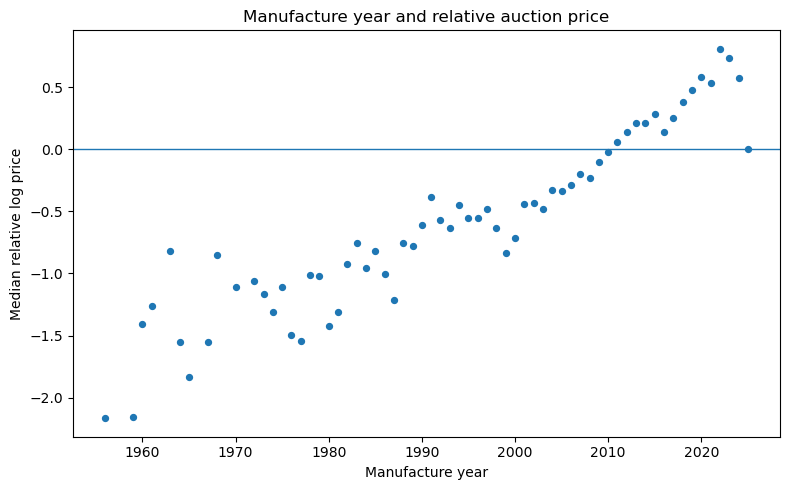

In [24]:
year_summary = (
    model_data.groupby("year")
    .agg(
        tractors=("price", "size"),
        median_relative_log_price=("relative_log_price", "median"),
    )
    .reset_index()
)

# Only years with at least 20 observations are shown to avoid unstable points.
year_plot = year_summary.loc[year_summary["tractors"] >= 20]

plt.figure(figsize=(8, 5))
plt.scatter(
    year_plot["year"],
    year_plot["median_relative_log_price"],
    s=18,
)
plt.axhline(0, linewidth=1)
plt.xlabel("Manufacture year")
plt.ylabel("Median relative log price")
plt.title("Manufacture year and relative auction price")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_price_vs_year.png", dpi=300, bbox_inches="tight")
plt.show()

## 21. Horsepower and price: a strong pattern with very sparse coverage

Horsepower is a plausible valuation variable and the recorded observations show a clear positive relationship with relative auction price. However, it is available for only a small fraction of the unique sales. Both the relationship and the missingness are reported because omitting the field from the model should not be mistaken for evidence that horsepower is unimportant.

The scatterplot uses all non-missing horsepower observations. Horsepower quantile summaries are also calculated and saved for the supporting EDA table, but no smoothed or binned trend is imposed on the scatterplot.

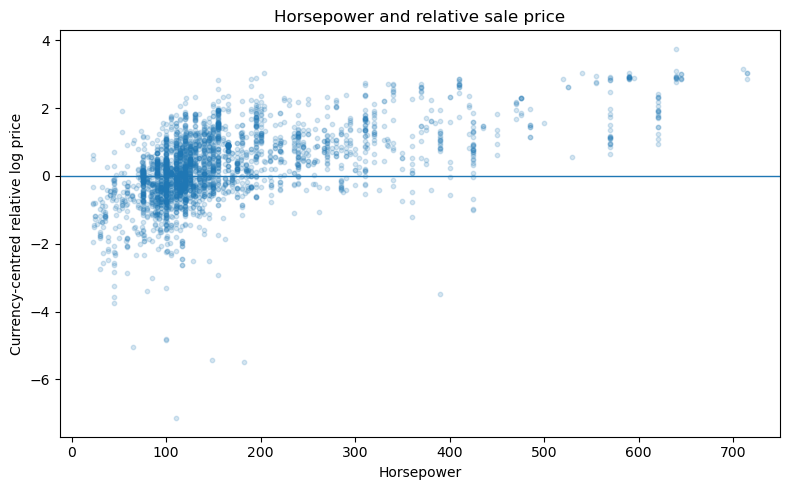

Horsepower coverage: 2,947 of 22,857 (12.9%)
Spearman correlation with relative log price: 0.580


,horsepower_band,tractors,median_horsepower,median_relative_log_price,median_price
0,"(21.999, 87.0]",371,75.000,-0.455,"17,000.000"
1,"(87.0, 100.0]",465,100.000,-0.039,"24,500.000"
2,"(100.0, 115.0]",404,110.000,-0.063,"26,000.000"
3,"(115.0, 125.0]",334,120.000,0.139,"33,000.000"
4,"(125.0, 145.0]",312,137.000,0.292,"32,000.000"
5,"(145.0, 175.0]",329,155.000,0.677,"42,000.000"
6,"(175.0, 270.0]",367,210.000,0.791,"56,000.000"
7,"(270.0, 715.0]",365,375.000,1.354,"116,000.000"


In [25]:
horsepower_plot = eda_data.dropna(subset=["horsepower"]).copy()

horsepower_bins = (
    horsepower_plot
    .assign(
        horsepower_band=pd.qcut(
            horsepower_plot["horsepower"],
            q=8,
            duplicates="drop",
        )
    )
    .groupby("horsepower_band", observed=True)
    .agg(
        tractors=("price", "size"),
        median_horsepower=("horsepower", "median"),
        median_relative_log_price=("relative_log_price", "median"),
        median_price=("price", "median"),
    )
    .reset_index()
)

horsepower_spearman = horsepower_plot[
    ["horsepower", "relative_log_price"]
].corr(method="spearman").iloc[0, 1]

horsepower_bins.to_csv(
    TABLE_DIR / "12_horsepower_price_by_quantile.csv", index=False
)

plt.figure(figsize=(8, 5))
plt.scatter(
    horsepower_plot["horsepower"],
    horsepower_plot["relative_log_price"],
    s=10,
    alpha=0.18,
)
plt.axhline(0, linewidth=1)
plt.xlabel("Horsepower")
plt.ylabel("Currency-centred relative log price")
plt.title("Horsepower and relative sale price")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "10_horsepower_price_relationship.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    f"Horsepower coverage: {len(horsepower_plot):,} of {len(eda_data):,} "
    f"({100 * len(horsepower_plot) / len(eda_data):.1f}%)"
)
print(
    "Spearman correlation with relative log price:",
    f"{horsepower_spearman:.3f}",
)
horsepower_bins

## 22. Transmission and price

Transmission is also sparsely recorded and contains both generic and manufacturer-specific labels. To avoid unstable comparisons, the plot shows only transmission categories with at least 20 observations. Prices are again centred within currency.

The comparison is descriptive. Transmission type is intertwined with manufacturer, model series, age, power and specification level, so the bars should not be interpreted as causal transmission premiums.

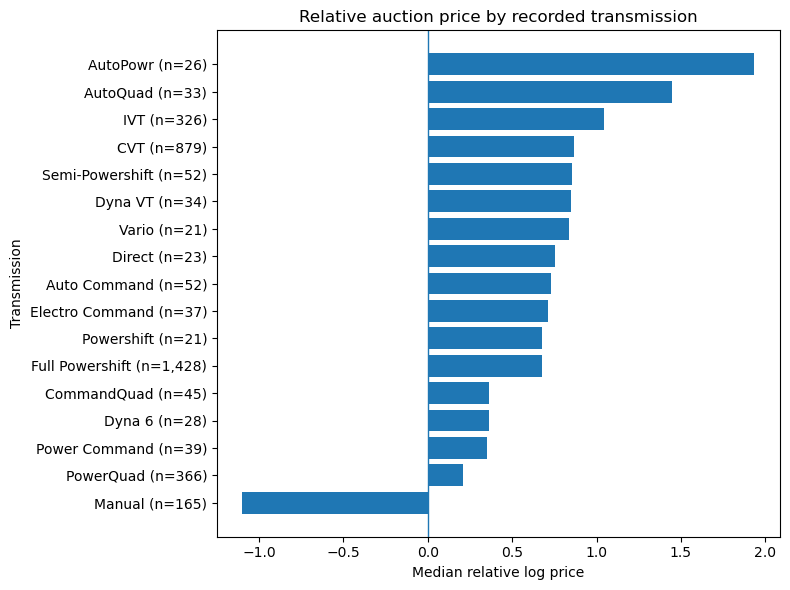

Transmission coverage: 3,666 of 22,857 (16.0%)


,tractors,median_relative_log_price,median_price
transmission,,,
Manual,165,-1.099,"4,400.000"
PowerQuad,366,0.210,"35,000.000"
Power Command,39,0.353,"33,000.000"
Dyna 6,28,0.361,"44,500.000"
CommandQuad,45,0.362,"56,000.000"
Full Powershift,1428,0.677,"64,000.000"
Powershift,21,0.677,"18,800.000"
Electro Command,37,0.712,"53,000.000"
Auto Command,52,0.731,"57,000.000"


In [26]:
transmission_summary = (
    eda_data.dropna(subset=["transmission"])
    .groupby("transmission")
    .agg(
        tractors=("price", "size"),
        median_relative_log_price=("relative_log_price", "median"),
        median_price=("price", "median"),
    )
    .sort_values("tractors", ascending=False)
)

transmission_summary.to_csv(
    TABLE_DIR / "13_transmission_price_summary.csv"
)

transmission_plot = (
    transmission_summary.loc[transmission_summary["tractors"] >= 20]
    .sort_values("median_relative_log_price")
    .copy()
)

transmission_plot["plot_label"] = [
    f"{name} (n={int(n):,})"
    for name, n in zip(
        transmission_plot.index,
        transmission_plot["tractors"],
    )
]

plt.figure(figsize=(8, 6))
plt.barh(
    transmission_plot["plot_label"],
    transmission_plot["median_relative_log_price"],
)
plt.axvline(0, linewidth=1)
plt.xlabel("Median relative log price")
plt.ylabel("Transmission")
plt.title("Relative auction price by recorded transmission")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "11_transmission_price_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print(
    "Transmission coverage:",
    f"{eda_data['transmission'].notna().sum():,} of {len(eda_data):,}",
    f"({100 * eda_data['transmission'].notna().mean():.1f}%)",
)
transmission_plot[[
    "tractors", "median_relative_log_price", "median_price"
]]

### Transmission association diagnostic

The transmission plot suggests sizeable price differences between recorded categories. As a descriptive check, a Kruskal--Wallis test is applied to the currency-centred relative log prices for transmission categories with at least 20 observations. Because several transmission names are manufacturer-specific, the analysis also reports how concentrated each transmission category is within a single manufacturer. The test is evidence of association, not a causal transmission premium.

In [27]:
from scipy.stats import kruskal

transmission_test_data = eda_data.loc[
    eda_data["transmission"].isin(transmission_plot.index),
    ["transmission", "make", "relative_log_price"],
].dropna()

transmission_groups = [
    group["relative_log_price"].to_numpy()
    for _, group in transmission_test_data.groupby("transmission")
]

kw_statistic, kw_pvalue = kruskal(*transmission_groups)
kw_k = len(transmission_groups)
kw_n = len(transmission_test_data)
kw_epsilon_squared = (kw_statistic - kw_k + 1) / (kw_n - kw_k)

transmission_make_table = pd.crosstab(
    transmission_test_data["transmission"],
    transmission_test_data["make"],
)
transmission_make_purity = (
    transmission_make_table.max(axis=1) / transmission_make_table.sum(axis=1)
)
weighted_make_concentration = (
    transmission_make_table.max(axis=1).sum() / transmission_make_table.to_numpy().sum()
)

transmission_association = pd.DataFrame({
    "measure": [
        "Transmission categories with at least 20 observations",
        "Observations in association test",
        "Kruskal-Wallis H statistic",
        "Kruskal-Wallis p-value",
        "Kruskal-Wallis epsilon-squared",
        "Weighted share in dominant manufacturer within category",
    ],
    "value": [
        kw_k,
        kw_n,
        kw_statistic,
        kw_pvalue,
        kw_epsilon_squared,
        weighted_make_concentration,
    ],
})

transmission_association.to_csv(
    TABLE_DIR / "13b_transmission_association_diagnostic.csv",
    index=False,
)

print(f"Kruskal-Wallis H = {kw_statistic:.1f}, p = {kw_pvalue:.3g}")
print(f"Epsilon-squared = {kw_epsilon_squared:.3f}")
print(
    "Weighted share in the dominant manufacturer within transmission category =",
    f"{100 * weighted_make_concentration:.1f}%",
)
transmission_association

Kruskal-Wallis H = 524.9, p = 1.81e-101
Epsilon-squared = 0.143
Weighted share in the dominant manufacturer within transmission category = 56.0%


,measure,value
0,Transmission categories with at least 20 obser...,17.000
1,Observations in association test,"3,575.000"
2,Kruskal-Wallis H statistic,524.918
3,Kruskal-Wallis p-value,0.000
4,Kruskal-Wallis epsilon-squared,0.143
5,Weighted share in dominant manufacturer within...,0.560


## 23. Is specification missingness random with respect to price?

A useful EDA check is whether tractors with a recorded specification look systematically different from tractors where the field is blank. Large differences would make simple imputation particularly risky because the observed subset may not be representative of the full market.

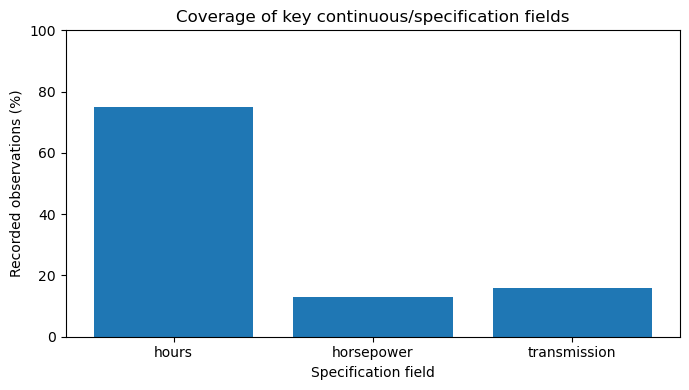

,field,recorded,tractors,percent_of_sample,median_relative_log_price,median_price
0,hours,Missing,5728,25.060,-0.960,"9,250.000"
1,hours,Recorded,17129,74.940,0.244,"34,000.000"
2,horsepower,Missing,19910,87.107,-0.043,"25,000.000"
3,horsepower,Recorded,2947,12.893,0.210,"33,000.000"
4,transmission,Missing,19191,83.961,-0.137,"22,500.000"
5,transmission,Recorded,3666,16.039,0.693,"54,000.000"


In [28]:
availability_rows = []

for field in ["hours", "horsepower", "transmission"]:
    source = model_data if field == "hours" else eda_data

    for available, group in source.groupby(source[field].notna()):
        availability_rows.append({
            "field": field,
            "recorded": "Recorded" if available else "Missing",
            "tractors": len(group),
            "percent_of_sample": 100 * len(group) / len(source),
            "median_relative_log_price": group["relative_log_price"].median(),
            "median_price": group["price"].median(),
        })

specification_availability_price = pd.DataFrame(availability_rows)
specification_availability_price.to_csv(
    TABLE_DIR / "14_specification_availability_and_price.csv",
    index=False,
)

plot_coverage = specification_coverage.set_index("field")["available_percent"]

plt.figure(figsize=(7, 4))
plt.bar(plot_coverage.index, plot_coverage.values)
plt.ylabel("Recorded observations (%)")
plt.xlabel("Specification field")
plt.title("Coverage of key continuous/specification fields")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "12_key_specification_coverage.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

specification_availability_price

## 24. Manufacturer composition

In [29]:
make_summary = (
    model_data.groupby("make")
    .agg(
        tractors=("price", "size"),
        median_relative_log_price=("relative_log_price", "median"),
    )
    .sort_values("tractors", ascending=False)
)

make_summary.to_csv(TABLE_DIR / "07_make_summary.csv")
make_summary.head(15)

,tractors,median_relative_log_price
make,,
John Deere,13428,0.098
New Holland,3549,-0.416
Case IH,1696,0.464
Massey Ferguson,1342,-0.445
Fendt,560,0.836
Claas,447,-0.039
Caterpillar,437,-1.548
Ford,356,-0.750
Deutz-Fahr,318,0.109


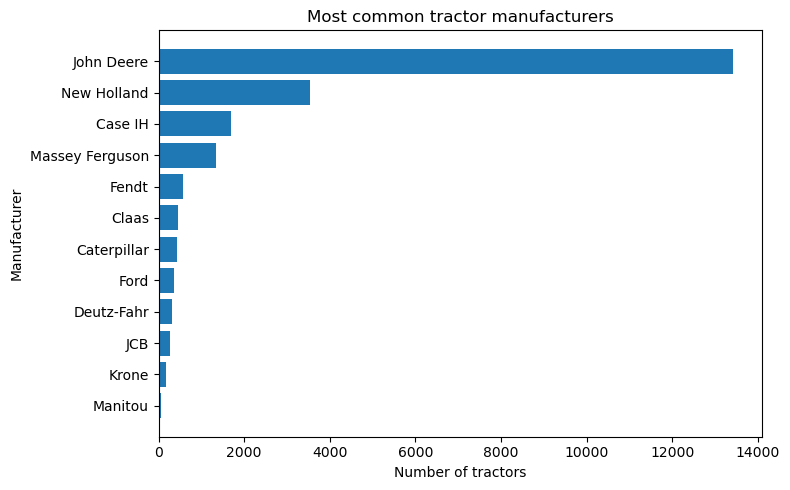

In [30]:
top_makes = make_summary.head(12).sort_values("tractors")

plt.figure(figsize=(8, 5))
plt.barh(top_makes.index, top_makes["tractors"])
plt.xlabel("Number of tractors")
plt.ylabel("Manufacturer")
plt.title("Most common tractor manufacturers")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_top_manufacturers.png", dpi=300, bbox_inches="tight")
plt.show()

## 25. Model-series frequency

`model_series` contains important information about the specific tractor model, but it is a high-cardinality variable. The frequency table below is used later to justify grouping very rare model series before modelling.

In [31]:
series_counts = model_data["model_series"].value_counts()

series_frequency_summary = pd.DataFrame({
    "measure": [
        "Unique model series",
        "Series appearing once",
        "Series with at least 5 observations",
        "Rows belonging to series with at least 5 observations",
    ],
    "value": [
        series_counts.size,
        int((series_counts == 1).sum()),
        int((series_counts >= 5).sum()),
        int(series_counts[series_counts >= 5].sum()),
    ],
})

series_frequency_summary.to_csv(
    TABLE_DIR / "08_model_series_frequency_summary.csv", index=False
)
series_frequency_summary

,measure,value
0,Unique model series,7889
1,Series appearing once,5081
2,Series with at least 5 observations,917
3,Rows belonging to series with at least 5 obser...,12883


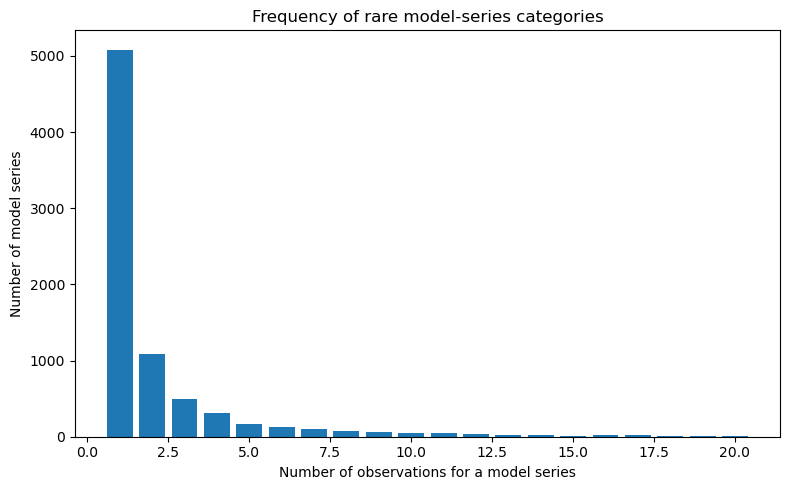

In [32]:
frequency_of_frequency = series_counts.value_counts().sort_index()
frequency_of_frequency = frequency_of_frequency.loc[frequency_of_frequency.index <= 20]

plt.figure(figsize=(8, 5))
plt.bar(frequency_of_frequency.index, frequency_of_frequency.values)
plt.xlabel("Number of observations for a model series")
plt.ylabel("Number of model series")
plt.title("Frequency of rare model-series categories")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_model_series_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

## 26. Drive type

Missing drive values have already been replaced by `4WD` using the supplied domain rule. The remaining comparison is therefore between the recorded drive categories.

In [33]:
drive_summary = (
    model_data.groupby("drive")
    .agg(
        tractors=("price", "size"),
        median_relative_log_price=("relative_log_price", "median"),
    )
    .sort_values("tractors", ascending=False)
)

drive_summary.to_csv(TABLE_DIR / "09_drive_summary.csv")
drive_summary

,tractors,median_relative_log_price
drive,,
4WD,22287,0.025
2WD,570,-1.285


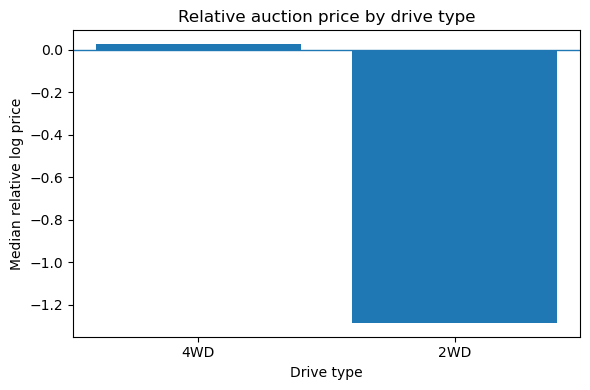

In [34]:
plt.figure(figsize=(6, 4))
plt.bar(drive_summary.index, drive_summary["median_relative_log_price"])
plt.axhline(0, linewidth=1)
plt.xlabel("Drive type")
plt.ylabel("Median relative log price")
plt.title("Relative auction price by drive type")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_drive_price_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 27. Boolean equipment indicators

For each specification indicator, the table records its prevalence and the median relative log price when the feature is present or absent. These are descriptive comparisons only; they do not isolate causal effects because equipment features are correlated with tractor age, make, model and other characteristics.

In [35]:
boolean_rows = []

for column in BOOLEAN_FEATURES:
    present = model_data.loc[model_data[column], "relative_log_price"]
    absent = model_data.loc[~model_data[column], "relative_log_price"]

    boolean_rows.append({
        "feature": column,
        "present_percent": 100 * model_data[column].mean(),
        "median_relative_log_price_present": present.median(),
        "median_relative_log_price_absent": absent.median(),
        "median_difference": present.median() - absent.median(),
    })

boolean_summary = (
    pd.DataFrame(boolean_rows)
    .sort_values("median_difference", ascending=False)
)

boolean_summary.to_csv(TABLE_DIR / "10_boolean_feature_summary.csv", index=False)
boolean_summary

,feature,present_percent,median_relative_log_price_present,median_relative_log_price_absent,median_difference
16,high_flow_hydraulics,2.166,1.396,-0.022,1.417
8,isobus,9.083,1.001,-0.108,1.109
6,air_conditioning,47.255,0.507,-0.568,1.074
15,rear_view_camera,6.545,0.937,-0.066,1.003
14,dual_tires,1.142,0.952,-0.022,0.973
4,cab_suspension,8.772,0.825,-0.089,0.914
9,adblue,5.119,0.776,-0.066,0.842
2,front_linkage,2.476,0.819,-0.022,0.841
3,front_axle_suspension,8.046,0.731,-0.080,0.811
12,load_sensing,4.410,0.749,-0.043,0.793


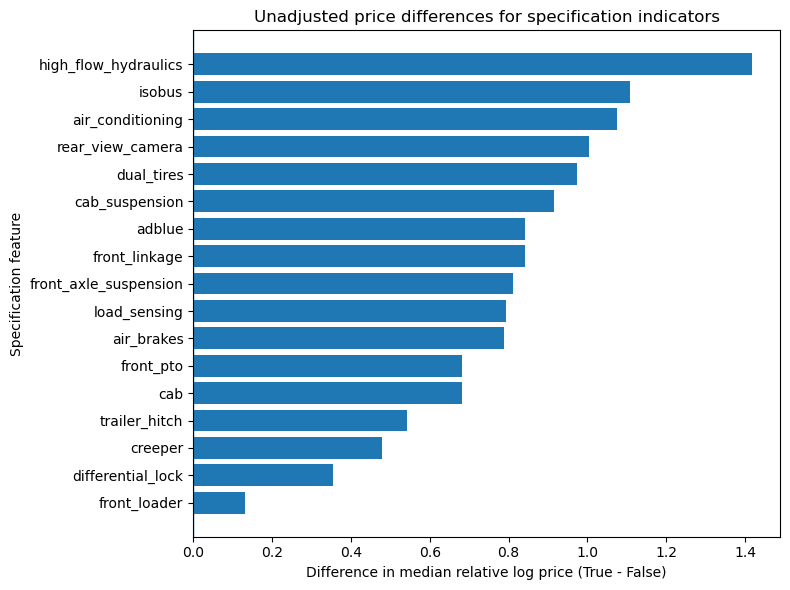

In [36]:
plot_boolean = boolean_summary.sort_values("median_difference")

plt.figure(figsize=(8, 6))
plt.barh(plot_boolean["feature"], plot_boolean["median_difference"])
plt.axvline(0, linewidth=1)
plt.xlabel("Difference in median relative log price (True - False)")
plt.ylabel("Specification feature")
plt.title("Unadjusted price differences for specification indicators")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_boolean_price_differences.png", dpi=300, bbox_inches="tight")
plt.show()

## 28. Correlation between Boolean indicators

This check is especially relevant for linear regression because closely related specification fields can contain overlapping information. The heatmap is descriptive and is used to identify obvious clusters of correlated indicators.

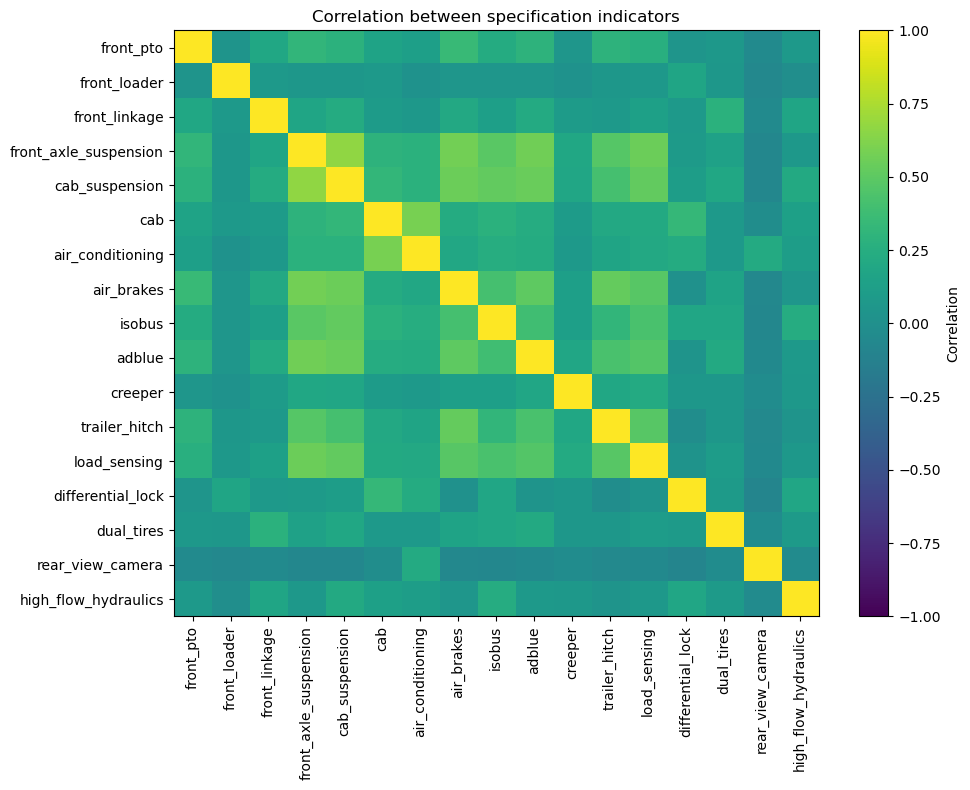

In [37]:
boolean_corr = model_data[BOOLEAN_FEATURES].astype(int).corr()
boolean_corr.to_csv(TABLE_DIR / "11_boolean_correlation_matrix.csv")

plt.figure(figsize=(10, 8))
plt.imshow(boolean_corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(BOOLEAN_FEATURES)), BOOLEAN_FEATURES, rotation=90)
plt.yticks(range(len(BOOLEAN_FEATURES)), BOOLEAN_FEATURES)
plt.title("Correlation between specification indicators")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "09_boolean_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

## 29. Inspect extreme observations

Extreme observations are saved for manual review rather than removed automatically. This is important for auction data: a high price, low price or high usage value can represent a genuine transaction rather than a data error. The modelling response transformation is therefore used to reduce the leverage of the price tail instead of deleting observations solely because they are statistically unusual.

In [38]:
extreme_prices = model_data.nlargest(25, "price")
extreme_hours = model_data.nlargest(25, "hours")

extreme_prices.to_csv(TABLE_DIR / "16_highest_price_observations.csv", index=False)
extreme_hours.to_csv(TABLE_DIR / "17_highest_hours_observations.csv", index=False)

extreme_prices[["make", "model_series", "year", "hours", "price", "currency"]].head(10)

,make,model_series,year,hours,price,currency
248,John Deere,9RX 710,2025,422.000,"905,000.000",CAD
249,John Deere,9RX 640,2023,110.000,"865,000.000",CAD
251,Case IH,Steiger 715 Quadtrac Track,2024,324.000,"820,000.000",CAD
9033,Case IH,Steiger 715 Quadtrac Track,2024,324.000,"820,000.000",CAD
250,John Deere,9RX 590,2024,351.000,"810,000.000",CAD
252,Case IH,Steiger 715 Quadtrac Track,2024,423.000,"810,000.000",CAD
9032,Case IH,Steiger 715 Quadtrac Track,2024,423.000,"810,000.000",CAD
9742,John Deere,616R Signature Edition,2025,89.000,"800,000.000",CAD
265,Case IH,Steiger 645 Quadtrac Track,2024,13.000,"785,000.000",CAD
9031,Case IH,Steiger 645 Quadtrac Track,2024,13.000,"785,000.000",CAD


## 30. Save the cleaned modelling data

The two temporary EDA columns (`log_price` and `relative_log_price`) are not predictors and are therefore removed before saving.

In [39]:
columns_to_save = MODELLING_COLUMNS
cleaned_data = model_data[columns_to_save].copy()

cleaned_data.to_csv(CLEAN_DATA_PATH, index=False)

print(f"Saved cleaned data to: {CLEAN_DATA_PATH}")
print(f"Final modelling rows: {len(cleaned_data):,}")
print(f"Final modelling columns: {cleaned_data.shape[1]}")

Saved cleaned data to: cleaned_tractors.csv
Final modelling rows: 22,857
Final modelling columns: 25


## 31. Files produced by this notebook

The notebook creates:

- `cleaned_tractors.csv` — the modelling dataset (horsepower and transmission remain excluded);
- `outputs/tables/` — cleaning audit, missingness, price summaries, category-frequency summaries, horsepower/transmission diagnostics and extreme-observation checks;
- `outputs/figures/` — report-ready EDA figures saved at 300 dpi.

The modelling notebook uses `cleaned_tractors.csv` as its input. The horsepower and transmission analyses remain EDA-only because their very high missingness prevents them from being used reliably across the full sample.